# Does excitement differ between rainy and drier days?

**Descriptive question:** Do students select “It is the most exciting” more often on rainy days?

**Prediction question:** Can daily rainfall predict whether a student selects this answer?

We match survey answers with Copenhagen rainfall, compare percentages, and train a simple logistic regression classifier. We compare its test accuracy with a baseline that always predicts the most common training answer.

Run cells from top to bottom with the working directory set to this notebook’s `assignment/` folder.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import requests
from pathlib import Path
from IPython.display import display


### Download or read the weather data
Source: [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), using **ECMWF ERA5** estimates for Copenhagen. `rain_sum` is daily rainfall in millimetres, using Copenhagen's local calendar day.

[Open the exact API request](https://archive-api.open-meteo.com/v1/archive?latitude=55.6761&longitude=12.5683&start_date=2020-08-26&end_date=2026-09-21&daily=rain_sum&timezone=Europe%2FCopenhagen&models=era5).

Historical daily rainfall data for Copenhagen, downloaded from Open-Meteo.

In [11]:
weather_file = Path("../dataset/copenhagen_weather_daily.csv")

# Reuse the saved CSV so the notebook also works offline.
if weather_file.exists():
    weather_df = pd.read_csv(weather_file)
    print("Loaded saved weather data.")
else:
    url = "https://archive-api.open-meteo.com/v1/archive"
    parameters = {
        "latitude": 55.6761,            # Copenhagen
        "longitude": 12.5683,
        "start_date": "2020-08-26",
        "end_date": "2026-09-21",
        "daily": "rain_sum",            # Daily rainfall in millimetres
        "timezone": "Europe/Copenhagen",
        "models": "era5",
    }
    response = requests.get(url, params=parameters, timeout=30)
    response.raise_for_status()

    # Turn the API response into a table and save it for next time.
    weather_df = pd.DataFrame(response.json()["daily"])
    weather_df = weather_df.rename(columns={"time": "date", "rain_sum": "rain_mm"})
    weather_df.to_csv(weather_file, index=False)

weather_df.head()


Loaded saved weather data.


,date,rain_mm
0,2020-08-26,8.6
1,2020-08-27,9.9
2,2020-08-28,2.7
3,2020-08-29,8.3
4,2020-08-30,0.6


### Read and combine the student data

The shared function in `load_student_data.py` reads all four formats, removes password columns, and combines the tables. Each call returns a fresh table.

In [12]:
from load_student_data import load_student_data

# Read and combine the four survey files using the shared Python function.
students_df = load_student_data()
print("Total responses:", len(students_df))

Total responses: 223


### Clean the dates
The file named 2023 contains answers from **2020, 2021, and 2023**. We use the timestamp year, not the filename.

The sources use different time zones. Convert to Copenhagen time before extracting the date. For older timestamps without a zone, we assume Copenhagen time. This is the longest cleaning step because each file uses a different format.

In [13]:
def to_copenhagen(timestamp, source):
    # Each survey file stores timestamps in a different format.
    if source == 2023:
        date = pd.to_datetime(timestamp, format="%d/%m/%Y %H:%M:%S")
        date = date.tz_localize("Europe/Copenhagen")
    elif source == 2024:
        # Replace the written time zone with its numeric offset.
        timestamp = timestamp.replace("GMT+3", "+0300")
        date = pd.to_datetime(timestamp, format="%Y/%m/%d %I:%M:%S %p %z")
    elif source == 2025:
        date = pd.to_datetime(timestamp)
    else:
        timestamp = timestamp.replace("PDT", "-0700")
        date = pd.to_datetime(timestamp, format="%Y/%m/%d %I:%M:%S %p %z")
    return date.tz_convert("Europe/Copenhagen")

# Convert first: changing time zones can also change the calendar date.
local_times = []
for timestamp, source in zip(students_df["timestamp"], students_df["source_file"]):
    local_times.append(to_copenhagen(timestamp, source))

students_df["local_time"] = local_times
students_df["date"] = students_df["local_time"].dt.strftime("%Y-%m-%d")
students_df["year"] = students_df["local_time"].dt.year
print(students_df["year"].value_counts().sort_index())


year
2020    50
2021     7
2023    33
2024    38
2025    50
2026    45
Name: count, dtype: int64


### Clean the reasons
Remove missing or blank answers rather than treating them as “not excited.” Convert text to lowercase and remove surrounding spaces.

Students could select several options. We check whether the exact option **“It is the most exciting”** appears anywhere in the answer. Other choices can appear alongside it. This measures selection of an option, not a person's mood.

In [14]:
# Treat missing reasons as empty text, then remove empty answers.
students_df["reason_clean"] = students_df["course_reason"].fillna("").str.lower().str.strip()
missing = students_df["reason_clean"] == ""
print("Excluded missing or blank answers:", missing.sum())
students_df = students_df.loc[~missing].copy()

# True means the student selected this option; False means they did not.
students_df["exciting"] = students_df["reason_clean"].str.contains(
    "it is the most exciting", regex=False
)


Excluded missing or blank answers: 0


### Match rainfall to each answer
Match by date. Several students can share one weather day, so the weather table must have unique dates. Check that every survey date has rainfall; missing weather must not be treated as a dry day.

For this comparison, **rainy means at least 1 mm**. The other group is labelled **below 1 mm**, because it can include a little rain. This is a chosen threshold.

In [15]:
# many_to_one checks that the weather table has only one row per date.
data = students_df.merge(weather_df, on="date", how="left", validate="many_to_one")
assert data["rain_mm"].notna().all(), "Some survey dates have no weather data."

# Start with the drier group, then label days with at least 1 mm as rainy.
data["rain_group"] = "Below 1 mm"
data.loc[data["rain_mm"] >= 1, "rain_group"] = "At least 1 mm"
print("Matched responses:", len(data))
print("Distinct weather days:", data["date"].nunique())


Matched responses: 223
Distinct weather days: 45


### Compare percentages
Each student counts once, even if they selected several reasons. We show both the number of students and the number of dates so the sample size is clear.

,students,days,selected_exciting,exciting_percent
rain_group,,,,
Below 1 mm,100,26,48,48.0
At least 1 mm,123,19,65,52.8


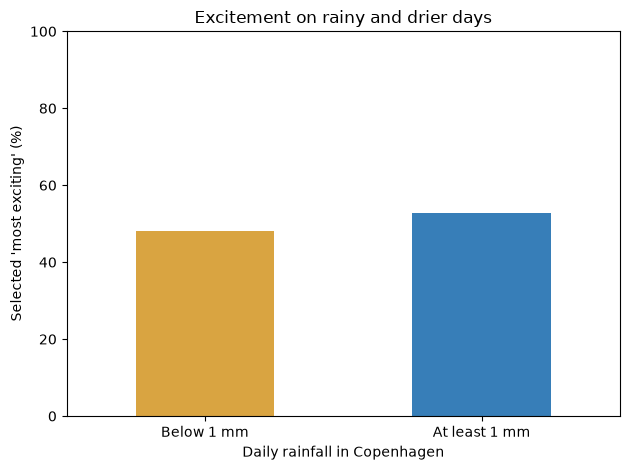

In [16]:
comparison = data.groupby("rain_group").agg(
    students=("exciting", "size"),
    days=("date", "nunique"),
    selected_exciting=("exciting", "sum"),
)
comparison["exciting_percent"] = 100 * comparison["selected_exciting"] / comparison["students"]
comparison = comparison.reindex(["Below 1 mm", "At least 1 mm"])
display(comparison.round(1))

comparison["exciting_percent"].plot.bar(color=["#d9a441", "#377eb8"], rot=0)
plt.ylabel("Selected 'most exciting' (%)")
plt.xlabel("Daily rainfall in Copenhagen")
plt.title("Excitement on rainy and drier days")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Check the years before interpreting the result
An apparent weather difference may instead be a difference between cohorts. The table below shows percentages within each year; blank cells mean that group has no responses.

In [17]:
by_year = data.pivot_table(index="year", columns="rain_group", values="exciting", aggfunc="mean") * 100
display(by_year.round(1))
print("Largest numbers of responses on a single day:")
display(data["date"].value_counts().head(3))

rain_group,At least 1 mm,Below 1 mm
year,,
2020,43.8,50.0
2021,NaN,71.4
2023,NaN,36.4
2024,50.0,47.2
2025,61.5,63.6
2026,55.9,54.5


Largest numbers of responses on a single day:


date
2020-08-26    47
2023-09-07    32
2025-09-02    23
Name: count, dtype: int64

### Descriptive answer

In [18]:
wet = comparison.loc["At least 1 mm", "exciting_percent"]
dry = comparison.loc["Below 1 mm", "exciting_percent"]

print(f"Selected 'most exciting' on rainy days: {wet:.1f}%")
print(f"Selected 'most exciting' on drier days: {dry:.1f}%")
print(f"Rainy minus drier: {wet - dry:+.1f} percentage points")


Selected 'most exciting' on rainy days: 52.8%
Selected 'most exciting' on drier days: 48.0%
Rainy minus drier: +4.8 percentage points


### Prepare a training/test split by date
Our only input is **rainfall in millimetres**. The target is **1 if “most exciting” was selected, 0 otherwise**. We use the rainfall amount, not the 1 mm threshold used for the bar chart.

Students answering on the same date share the same weather. `GroupShuffleSplit` keeps a whole date in either training or testing. We hold out **20% of dates**, so the percentage of students held out may differ. The split is fixed with `random_state=42`.

This tests prediction for held-out survey dates, not forecasting future cohorts.

In [19]:
from sklearn.model_selection import GroupShuffleSplit

X = data[["rain_mm"]]
y = data["exciting"].astype(int)

split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_rows, test_rows = next(split.split(X, y, groups=data["date"]))

X_train, X_test = X.iloc[train_rows], X.iloc[test_rows]
y_train, y_test = y.iloc[train_rows], y.iloc[test_rows]

# Check that no survey date appears in both groups.
train_dates = set(data.iloc[train_rows]["date"])
test_dates = set(data.iloc[test_rows]["date"])
assert train_dates.isdisjoint(test_dates)

print(f"Training: {len(y_train)} students on {len(train_dates)} dates")
print(f"Testing: {len(y_test)} students on {len(test_dates)} dates")
print("Test answer counts (0 = not selected, 1 = selected):")
print(y_test.value_counts().sort_index())

Training: 194 students on 36 dates
Testing: 29 students on 9 dates
Test answer counts (0 = not selected, 1 = selected):
exciting
0    12
1    17
Name: count, dtype: int64


### Scale rainfall and train logistic regression
Despite its name, **logistic regression is a classification model**. It learns how rainfall relates to the probability of selecting “most exciting.” `.predict()` chooses 1 when that probability is above 0.5, otherwise 0.

`StandardScaler` learns the mean and standard deviation from training rainfall only. Apply that same scaling to the test data. We use the default logistic regression settings without tuning them on the test results.

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train_scaled, y_train)
predictions = model.predict(X_test_scaled)

print("First five predictions:", predictions[:5])
print("First five actual answers:", y_test.to_numpy()[:5])

First five predictions: [0 0 0 0 0]
First five actual answers: [0 1 0 1 1]


### Compare with a baseline
`DummyClassifier` always predicts the most common answer in the **training set**, without using rainfall. Both methods are tested on the same students.

Accuracy is the percentage predicted correctly. The confusion table shows whether the model recognizes both selected and unselected answers. The test set may have a different balance of answers from the training set, so the baseline need not reach 50% test accuracy.

In [21]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
model_accuracy = accuracy_score(y_test, predictions)

ml_comparison = pd.DataFrame({
    "Method": ["Most common answer baseline", "Logistic regression"],
    "Test accuracy (%)": [100 * baseline_accuracy, 100 * model_accuracy],
})
display(ml_comparison.round(1))

# Rows show actual answers; columns show model predictions.
display(pd.DataFrame(
    confusion_matrix(y_test, predictions, labels=[0, 1]),
    index=["Actual: not selected", "Actual: selected"],
    columns=["Predicted: not selected", "Predicted: selected"],
))
print(f"Model minus baseline: {100 * (model_accuracy - baseline_accuracy):+.1f} percentage points")

,Method,Test accuracy (%)
0,Most common answer baseline,41.4
1,Logistic regression,37.9


,Predicted: not selected,Predicted: selected
Actual: not selected,9,3
Actual: selected,15,2


Model minus baseline: -3.4 percentage points


### Interpreting the prediction result
**Result:** logistic regression predicted **11 of 29 answers correctly (37.9%)**, compared with **12 of 29 (41.4%)** for the baseline. Rainfall alone did not improve prediction on this split. The difference is just one student, and the test students come from only nine dates, so this does not establish a general absence of a weather relationship.

This is a retrospective exercise: a full-day rain total can include rain after an answer. Year and programme are not included as predictors, so differences between cohorts could explain any apparent relationship. Students from each test day still share weather; they are not independent weather observations.

### Limitations
Neither the descriptive comparison nor the classifier establishes that rain changes students' motivation.

- Students from the same day share the same weather. The 223 responses cover only 45 dates; 47 answers come from one day in 2020.
- Years and programmes may explain the difference. We have not performed a significance test or established causation.
- We assume respondents were in Copenhagen. A daily total can include rain after the answer was submitted.
- Choosing “most exciting” is not a direct measurement of mood. The result also depends on our 1 mm threshold.

**Conclusion:** this notebook answers what happened in this sample. It does not establish a general weather effect.